<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%B0%D1%806_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [50]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [51]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [52]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [53]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [54]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [55]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [56]:
# TODO: підрахуйте частоти категорій у gender.
print("Частоти категорій gender:")
print(df['gender'].value_counts())

Частоти категорій gender:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [57]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("\nЧастоти категорій smoking_history:")
print(df['smoking_history'].value_counts())


Частоти категорій smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [58]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [59]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [60]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [61]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [62]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [63]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [64]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [65]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

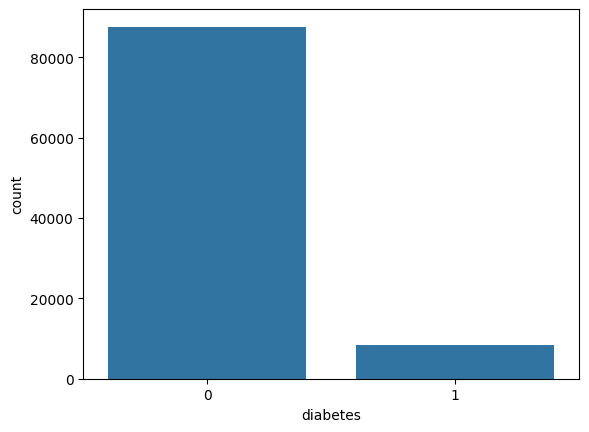

In [66]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [67]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [68]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.

from sklearn.model_selection import train_test_split

X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (76916, 8)
X_test: (19230, 8)
y_train: (76916,)
y_test: (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [69]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

X_train = pd.get_dummies(
    X_train,
    columns=['gender', 'smoking_history'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['gender', 'smoking_history'],
    dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Кількість ознак у X_train:", X_train.shape[1])
print("Кількість ознак у X_test:", X_test.shape[1])

print("\nСтовпці X_train:")
print(X_train.columns.tolist())

Кількість ознак у X_train: 15
Кількість ознак у X_test: 15

Стовпці X_train:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


In [70]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [71]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
correlation_with_target = X_train.corrwith(y_train)

correlation_with_target = correlation_with_target.reindex(
    correlation_with_target.abs().sort_values(ascending=False).index
)

print("Кореляція ознак із diabetes:")
print(correlation_with_target)

Кореляція ознак із diabetes:
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_No Info       -0.113053
smoking_history_former         0.096162
gender_Male                    0.040650
gender_Female                 -0.040533
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
dtype: float64


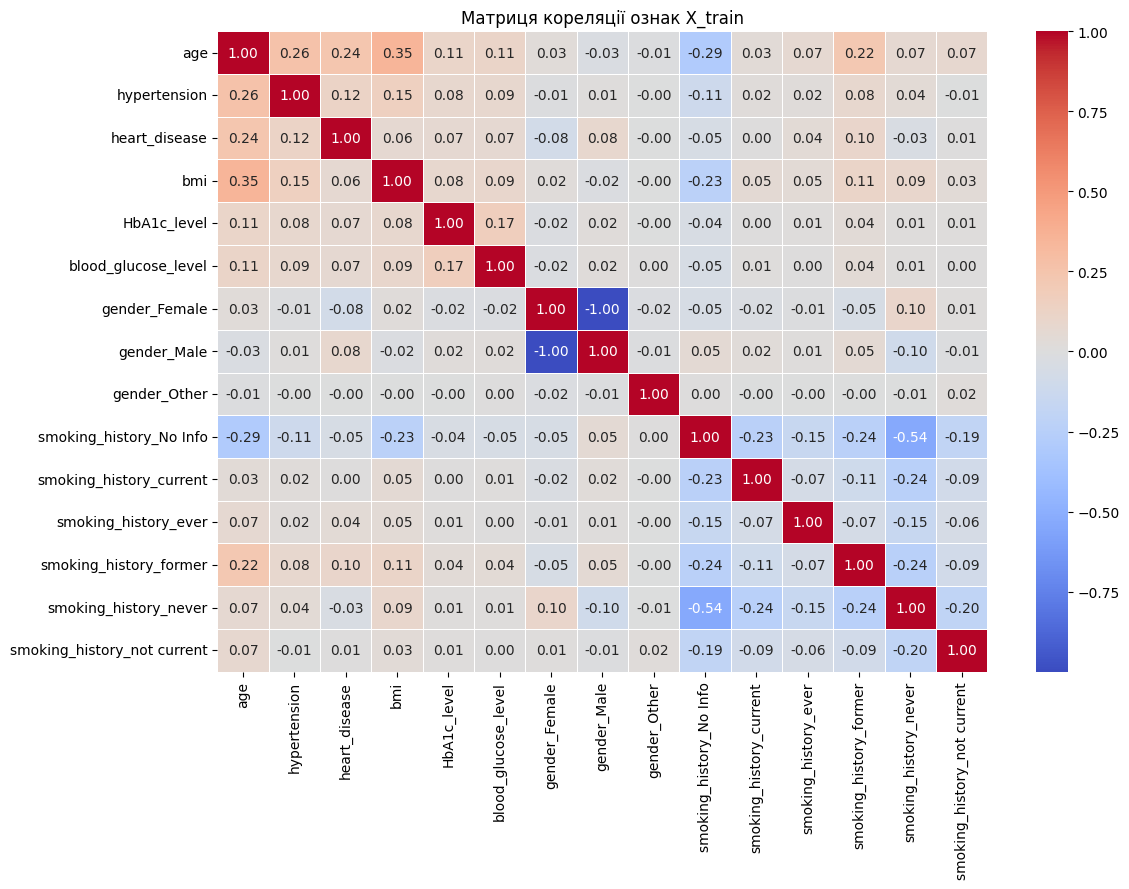

In [72]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
correlation_matrix = X_train.corr()

correlation_matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Матриця кореляції ознак X_train')
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']


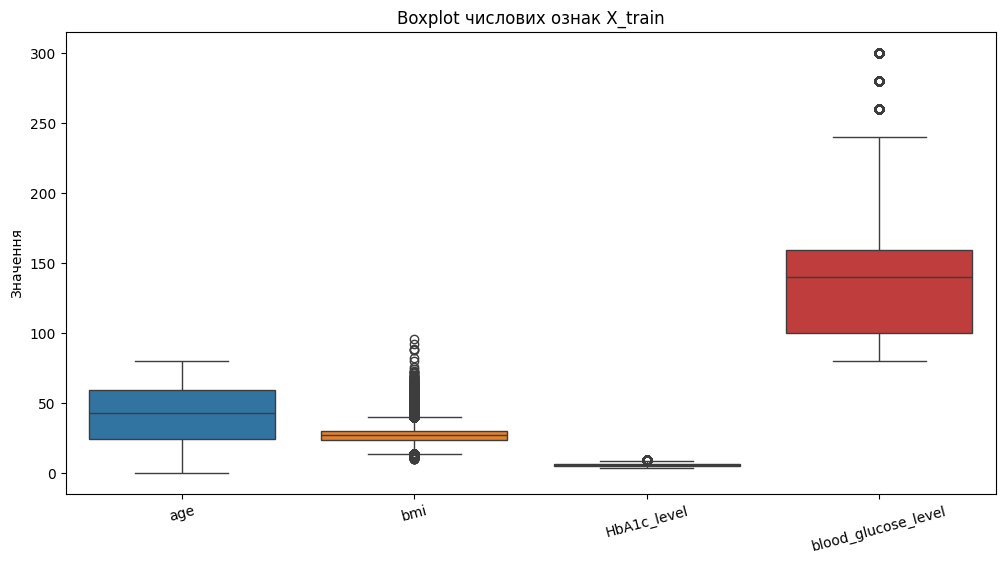

In [73]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

print(continuous_cols)

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_train[continuous_cols])

plt.title('Boxplot числових ознак X_train')
plt.xticks(rotation=15)
plt.ylabel('Значення')
plt.show()

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [74]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [75]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
skewness = X_train[continuous_cols].skew()

print("Асиметрія розподілів:")
print(skewness)

Асиметрія розподілів:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [76]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропущені значення X_train:")
print(X_train.isnull().sum())

print("\nПропущені значення X_test:")
print(X_test.isnull().sum())

Пропущені значення X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропущені значення X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [77]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Розмір X_train_scaled:", X_train_scaled.shape)
print("Розмір X_test_scaled:", X_test_scaled.shape)

Розмір X_train_scaled: (76916, 15)
Розмір X_test_scaled: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

Кількість класів до балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів після балансування:
diabetes
0    70130
1    70130
Name: count, dtype: int64


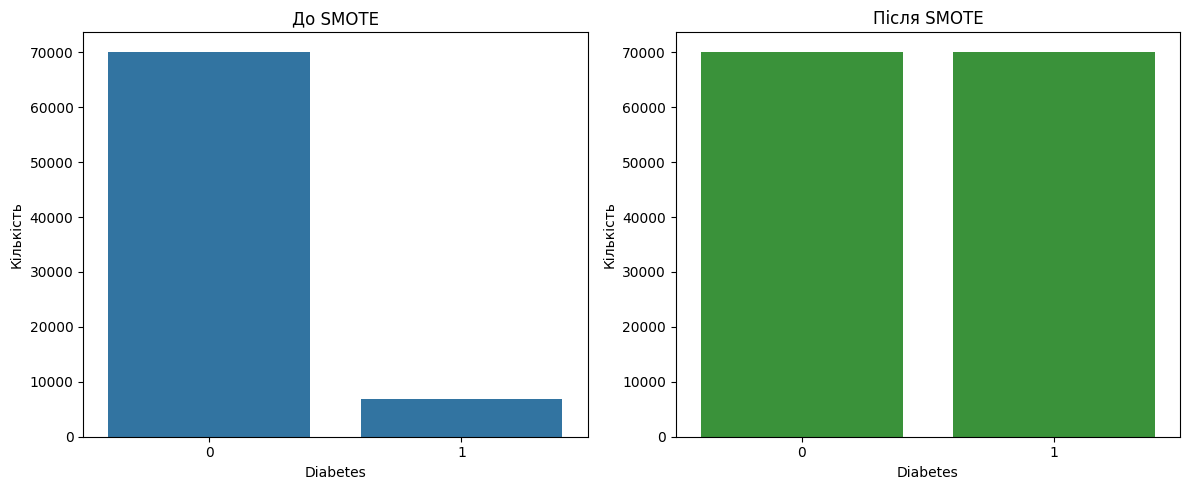

In [78]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
from imblearn.over_sampling import SMOTE

print("Кількість класів до балансування:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nКількість класів після балансування:")
print(y_train_smote.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, color='tab:blue', ax=axes[0])
axes[0].set_title('До SMOTE')
axes[0].set_xlabel('Diabetes')
axes[0].set_ylabel('Кількість')

sns.countplot(x=y_train_smote, color='tab:green', ax=axes[1])
axes[1].set_title('Після SMOTE')
axes[1].set_xlabel('Diabetes')
axes[1].set_ylabel('Кількість')

plt.tight_layout()
plt.show()

Оголошуємо моделі

In [81]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC

models = {
    'LogisticRegression': LogisticRegression(
        random_state=42,
        max_iter=2000
    ),

    'RidgeClassifier': RidgeClassifier(),

    'SGDClassifier': SGDClassifier(
        random_state=42,
        max_iter=2000,
        tol=1e-3
    ),

    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Початок навчання: LogisticRegression
LogisticRegression успішно навчена за 0.16 секунд

Початок навчання: RidgeClassifier
RidgeClassifier успішно навчена за 0.11 секунд

Початок навчання: SGDClassifier
SGDClassifier успішно навчена за 0.27 секунд

Початок навчання: SVC
SVC успішно навчена за 262.48 секунд

========== LogisticRegression ==========
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



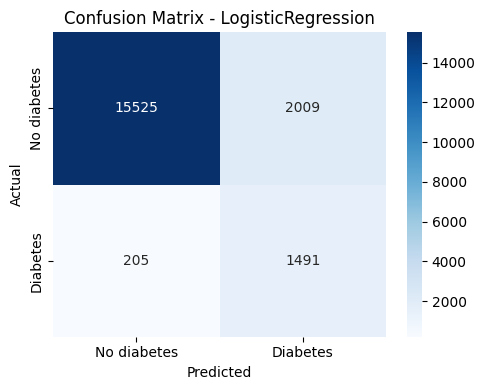


========== RidgeClassifier ==========
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



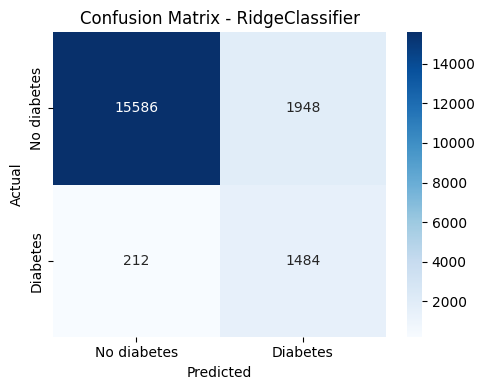


========== SGDClassifier ==========
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



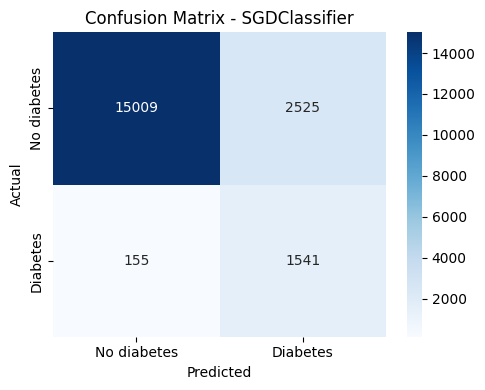


========== SVC ==========
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



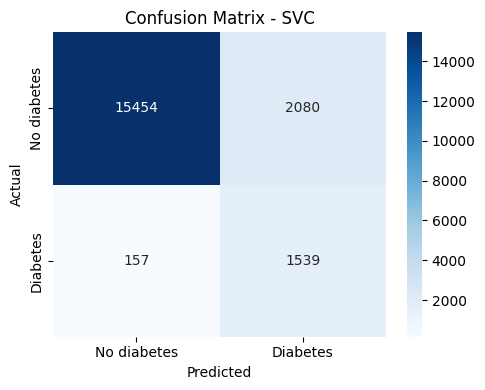

In [82]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
import time

for name, model in models.items():

    print(f'\nПочаток навчання: {name}', flush=True)

    start = time.time()

    model.fit(X_train_smote, y_train_smote)

    end = time.time()

    print(f'{name} успішно навчена за {end - start:.2f} секунд', flush=True)

from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    print(f'\n========== {name} ==========')

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No diabetes', 'Diabetes'],
        yticklabels=['No diabetes', 'Diabetes']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [83]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
# Словник параметрів для підбору гіперпараметрів
param_grids = {

    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['lbfgs', 'liblinear'],
        'penalty': ['l2']
    },

    'RidgeClassifier': {
        'alpha': [0.01, 0.1, 1, 10, 100]
    },

    'SGDClassifier': {
        'loss': ['hinge', 'log_loss'],
        'penalty': ['l1', 'l2', 'elasticnet'],
        'alpha': [0.0001, 0.001, 0.01, 0.1]
    },

    'SVC': [
        {
            'C': [0.1, 1, 10, 100],
            'kernel': ['linear']
        },
        {
            'C': [0.1, 1, 10, 100],
            'kernel': ['rbf'],
            'gamma': ['scale', 'auto']
        }
    ]
}

print("Словник параметрів створено.")

print("Моделі:")
for name in models:
    print(name)

print("\nПараметри для підбору:")
for name, params in param_grids.items():
    print(f"\n{name}:")
    print(params)

Словник параметрів створено.
Моделі:
LogisticRegression
RidgeClassifier
SGDClassifier
SVC

Параметри для підбору:

LogisticRegression:
{'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear'], 'penalty': ['l2']}

RidgeClassifier:
{'alpha': [0.01, 0.1, 1, 10, 100]}

SGDClassifier:
{'loss': ['hinge', 'log_loss'], 'penalty': ['l1', 'l2', 'elasticnet'], 'alpha': [0.0001, 0.001, 0.01, 0.1]}

SVC:
[{'C': [0.1, 1, 10, 100], 'kernel': ['linear']}, {'C': [0.1, 1, 10, 100], 'kernel': ['rbf'], 'gamma': ['scale', 'auto']}]


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [84]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [85]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
# Дозволяємо використання HalvingGridSearchCV
# Словник моделей
models = {
    'LogisticRegression': LogisticRegression(
        random_state=42,
        max_iter=2000
    ),

    'RidgeClassifier': RidgeClassifier(),

    'SGDClassifier': SGDClassifier(
        random_state=42,
        max_iter=2000,
        tol=1e-3
    ),

    'SVC': SVC()
}

best_models = {}
best_scores = {}

param_grids_pipeline = {

    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['lbfgs', 'liblinear'],
        'model__penalty': ['l2']
    },

    'RidgeClassifier': {
        'model__alpha': [0.01, 0.1, 1, 10, 100]
    },

    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l1', 'l2', 'elasticnet'],
        'model__alpha': [0.0001, 0.001, 0.01, 0.1]
    },

    'SVC': [
        {
            'model__C': [0.1, 1, 10, 100],
            'model__kernel': ['linear']
        },
        {
            'model__C': [0.1, 1, 10, 100],
            'model__kernel': ['rbf'],
            'model__gamma': ['scale', 'auto']
        }
    ]
}

for name, model in models.items():

    print(f'\n========== {name} ==========')

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids_pipeline[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Найкращі параметри:")
    print(search.best_params_)

    print("Найкращий середній F1 на крос-валідації:")
    print(search.best_score_)

    y_pred = search.best_estimator_.predict(X_test)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


========== LogisticRegression ==========
Найкращі параметри:
{'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Найкращий середній F1 на крос-валідації:
0.5715478166225

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


========== RidgeClassifier ==========
Найкращі параметри:
{'model__alpha': 10}
Найкращий середній F1 на крос-валідації:
0.5591088491898629

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94   

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [89]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
# Вибір найкращої моделі за F1
best_model_name = max(best_scores, key=best_scores.get)

best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print("Найкращий середній F1:", best_scores[best_model_name])

Найкраща модель: SGDClassifier
Найкращий середній F1: 0.5899045117932951


In [90]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
# Вибір 10 випадкових індексів тестової вибірки
random_indices = X_test.sample(
    n=10,
    random_state=42
).index

X_sample = X_test.loc[random_indices]

y_true = y_test.loc[random_indices]

y_pred = best_model.predict(X_sample)

results = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': y_true.values,
    'Передбачений клас': y_pred
})

print("Порівняння фактичних та передбачених значень:")
display(results)

Порівняння фактичних та передбачених значень:


,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики